In [ ]:
import requests
from pathlib import Path
import pandas as pd
import zipfile
%pip install remotezip
from remotezip import RemoteZip
import random
import shutil
%pip install h5py
import h5py
import numpy as np
from matplotlib import pyplot as plt
%pip install tifffile scikit-image
import tifffile


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python3.10 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python3.10 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python3.10 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
ERROR: Could not find a version that satisfies the requirement random (from versions: none)

[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python3.10 -m pip install --upgrade pip
ERROR: No matching distribution found for random
Note: you may need to restart the kernel to use updated packages.


1) Locate Dataset, Download annotation ZIP file, and Download Anntoation

In [7]:
#Get dataset
record = "14551288"
url = f"https://zenodo.org/api/records/{record}"
response = requests.get(url)
data = response.json()

#set directory for downloads
download_dir = Path("data")
download_dir.mkdir(exist_ok=True)

#download annotations zip
file = next(f for f in data["files"] if f["key"] == "Annotations_CSV.zip")
file_url = file["links"] = file["links"]["self"]
file_path = download_dir / file["key"]
with requests.get(file_url, stream=True) as r:
    r.raise_for_status()
    with open(file_path, "wb") as f:
        for chunk in r.iter_content(chunk_size=1024*1024):
            if chunk:
                f.write(chunk)


#Extract annotation file
ann_extract_path = Path("data/annotations")
with zipfile.ZipFile(file_path, "r") as ann_zip:
    ann_zip.extractall(ann_extract_path)

#Download annotation CSV
metadata = pd.read_csv("data/annotations/Annotations_CSV/Semantic annotation/Phase annotation.csv")

2) Partial extract files from cropped cell video zip file, and randomly identify videos to download that meet the required conditions

In [ ]:
#Set zip file variable
cell_zip_files = ["Eosinophils_crops.zip"]

#Select number of files to select
num_files = 5

#Identify videos to exclude 
ex_videos = ["Neu7", "Neu11", "Neu17"]

#Set randomizer
random.seed(42)

#Set URL location and partially extract identified video files
selected_files = {}

for cell_name in cell_zip_files:
    file = next(f for f in data["files"] if f["key"] == cell_name)
    file_url = file["links"]["self"]

    with RemoteZip(file_url) as z:

        #Do not include cell videos that have mutliple cells in each cropped video
        files = [f for f in z.infolist() if not f.is_dir() and f.filename.count("_cell") == 1]

        valid_files = []

        for f in files:
            #Get video ID and cell number from filename
            video_name = Path(f.filename).stem
            video_id = video_name.split("_cell")[0]
            cell_num = int(video_name.split("_cell")[1])

            #Exclude specific videos
            if video_id.lower() in [v.lower() for v in ex_videos]:
                continue

            #Find annotations for video ID
            rows = metadata[
                metadata["Video ID"].str.strip().str.lower() == video_id.lower()
                ].reset_index(drop=True)

            #Skip if the cell has no annotation
            if cell_num > len(rows):
                continue

            #Match cell to annotation row
            row = rows.iloc[cell_num - 1]

            #Exract frame boundaries
            frames = {
                "predeath": 1,
                "blebbing_start": row["blebbing (start frame)"],
                "blebbing_end": row["blebbing (end frame)"],
                "disruption_start": row["disruption (start frame)"],
                "disruption_end": row["disruption (end frame)"]
            }

            #Skip videos with missing frame annotations
            if any(pd.isna(frame) for frame in frames.values()):
                continue

            #Skip videos where blebbing starts at frame 1
            if frames["blebbing_start"] <= 1:
                continue

            #Keep videos that meet all conditions
            valid_files.append(f)

        #Print number of eligible files for download
        print(f"\n{cell_name}: {len(valid_files)} eligible files")

        #Randomly select from identified files
        selected = random.sample(valid_files, min(num_files, len(valid_files)))

        selected_files[cell_name] = [f.filename for f in selected]

        #Print file names
        for f in selected:
            print(f.filename, round(f.file_size / 1e6, 2), "MB")



Eosinophils_crops.zip: 7 eligible files
Eosinophils_crops/EOS4_cell2.ims 139.45 MB
Eosinophils_crops/EOS2_cell4.ims 211.45 MB
Eosinophils_crops/EOS5_cell1.ims 226.79 MB
Eosinophils_crops/EOS3_cell4.ims 312.79 MB
Eosinophils_crops/EOS4_cell1.ims 145.38 MB


3) Download identified files and store in data in cropp videos folder

In [ ]:
#Download selected files. Note takes approximately 1-2 minute per file download

#Create download path
download_dir = Path("data/cropped_videos")

#Find identified files and download video crop
for cell_name in cell_zip_files:

    file = next(f for f in data["files"] if f["key"] == cell_name)
    file_url = file["links"]["self"]

    # Create folders for each cell type
    cell_type = cell_name.replace("_crops.zip", "")
    output_dir = download_dir / cell_type
    output_dir.mkdir(parents=True, exist_ok=True)

    with RemoteZip(file_url) as z:

        for filename in selected_files[cell_name]:

            output_path = output_dir / filename
            output_path.parent.mkdir(parents=True, exist_ok=True)

            with z.open(filename) as source:
                with open(output_path, "wb") as destination:
                    shutil.copyfileobj(source, destination)

            print("Downloaded:", output_path)



Downloaded: data/cropped_videos/Eosinophils/Eosinophils_crops/EOS4_cell2.ims
Downloaded: data/cropped_videos/Eosinophils/Eosinophils_crops/EOS2_cell4.ims
Downloaded: data/cropped_videos/Eosinophils/Eosinophils_crops/EOS5_cell1.ims
Downloaded: data/cropped_videos/Eosinophils/Eosinophils_crops/EOS3_cell4.ims
Downloaded: data/cropped_videos/Eosinophils/Eosinophils_crops/EOS4_cell1.ims


In [11]:
#store video files
crop_dir = Path("data/cropped_videos")
video_files = list(crop_dir.rglob("*.ims"))

4) Extract predeath, blebbing, and disruption frames, convert to 2D images, and save to frames folder

In [ ]:
#Create frames directory
frames_dir = Path("data/frames")
frames_dir.mkdir(parents=True, exist_ok=True)

#set picture pixel crop size
crop_size = 100

#for each video identify its annotation and extract frames to convert to 2d images
for video_path in video_files:

    video_id = video_path.stem.split("_cell")[0]
    cell_num = int(video_path.stem.split("_cell")[1])

    #get video ID
    rows = metadata[
        metadata["Video ID"].str.lower() == video_id.lower()
    ].reset_index(drop=True)

    if cell_num > len(rows):
        print("No matching annotation:", video_path.name)
        continue

    #identify annotation row for that cell
    row = rows.iloc[cell_num - 1]

    #extract frame information 
    frames = {
        "predeath": 1,
        "blebbing_start": row["blebbing (start frame)"],
        "blebbing_end": row["blebbing (end frame)"],
        "disruption_start": row["disruption (start frame)"],
        "disruption_end": row["disruption (end frame)"]
    }

    #Extract channel information
    channel = int(row["Channel"].lower().replace("ch", "").split("/")[0]) - 1

    # Locate Position CSV for the correct video and channel
    folder_name = f"{video_id}_ch{channel + 1}"

    position_files = [
    p for p in ann_extract_path.rglob("*.csv")
    if folder_name.lower() in [part.lower() for part in p.parts]
    and p.stem.lower() == "position"
]


    positions = pd.read_csv(position_files[0])

    # Use first available tracked position
    positions = positions.sort_values("Time")

    #get position coordinates in um
    position = positions.iloc[0]
    x_um = position["Position X"]
    y_um = position["Position Y"]


    #extract frames from video
    with h5py.File(video_path, "r") as video:

        dataset = video["DataSet/ResolutionLevel 0"]
        
        for label, frame_num in frames.items():

            #Skip missing annotations
            if pd.isna(frame_num):
                continue

            #Assumes annotation frames start at 1
            t = int(frame_num) - 1

            frame_path = f"TimePoint {t}/Channel {channel}/Data"

            if frame_path not in dataset:
                print("Missing frame:", video_path.name, frame_path)
                continue

            #Read 3D frame
            frame = dataset[frame_path][:]

            #Convert to 2D image
            image_2d = np.mean(frame, axis=0)

            # Crop center of image
            half = crop_size // 2

            height, width = image_2d.shape

            # Find center coordinates
            x_pixel = width // 2
            y_pixel = height // 2

            # Crop 65 x 65 pixels
            cropped = image_2d[
                y_pixel - half:y_pixel + half + 1,
                x_pixel - half:x_pixel + half + 1
            ]

            #Save image with label
            filename = f"{video_id}_cell{cell_num}_{label}.png"

            filename = f"{video_id}_cell{cell_num}_{label}.tif"

            # Save TIFF (preserves original intensity values)
            tifffile.imwrite(
                frames_dir / f"{filename}.tif",
                cropped
            )

            # Save PNG (for easy viewing)
            plt.imsave(
                frames_dir / f"{filename}.png",
                cropped,
                cmap="gray"
            )

            print("Saved:", filename)    

Saved: EOS4_cell1_predeath.tif
Saved: EOS4_cell1_blebbing_start.tif
Saved: EOS4_cell1_blebbing_end.tif
Saved: EOS4_cell1_disruption_start.tif
Saved: EOS4_cell1_disruption_end.tif
Saved: EOS2_cell4_predeath.tif
Saved: EOS2_cell4_blebbing_start.tif
Saved: EOS2_cell4_blebbing_end.tif
Saved: EOS2_cell4_disruption_start.tif
Saved: EOS2_cell4_disruption_end.tif
Saved: EOS4_cell2_predeath.tif
Saved: EOS4_cell2_blebbing_start.tif
Saved: EOS4_cell2_blebbing_end.tif
Saved: EOS4_cell2_disruption_start.tif
Saved: EOS4_cell2_disruption_end.tif
Saved: EOS5_cell1_predeath.tif
Saved: EOS5_cell1_blebbing_start.tif
Saved: EOS5_cell1_blebbing_end.tif
Saved: EOS5_cell1_disruption_start.tif
Saved: EOS5_cell1_disruption_end.tif
Saved: EOS3_cell4_predeath.tif
Saved: EOS3_cell4_blebbing_start.tif
Saved: EOS3_cell4_blebbing_end.tif
Saved: EOS3_cell4_disruption_start.tif
Saved: EOS3_cell4_disruption_end.tif


## 5) Image filtering and feature extraction

Now doing the image filtering for each fram located in the folder `data/frames`. This is pre-requisite for doing the feature extraction process later on.

In [34]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import tifffile
from matplotlib import pyplot as plt
from scipy import ndimage as ndi
from skimage import color, feature, filters, io, util

frames_dir = Path("data/frames")
feature_extraction_dir = Path("data/features")
filtered_dir = feature_extraction_dir / "filtered"
for directory in (feature_extraction_dir, filtered_dir):
    directory.mkdir(parents=True, exist_ok=True)

phase_path = Path("data/annotations/Annotations_CSV/Semantic annotation/Phase annotation.csv")
if phase_path.exists():
    phase_annotations = pd.read_csv(phase_path) 

label_columns = {
    "blebbing_start": "blebbing (start frame)",
    "blebbing_end": "blebbing (end frame)",
    "disruption_start": "disruption (start frame)",
    "disruption_end": "disruption (end frame)",
}
pattern = re.compile(r"^(?P<video>.+)_cell(?P<cell>\d+)_(?P<label>predeath|blebbing_start|blebbing_end|disruption_start|disruption_end)$", re.I)

def describe_frame(path):
    result = {"image_path": str(path), "image_format": path.suffix.lower().lstrip("."), "video_id": None, "cell_num": None, "label": None, "frame_number": np.nan, "annotation_channel": None}
    name = path.name
    while Path(name).suffix.lower() in {".png", ".tif", ".tiff"}:
        name = Path(name).stem
    match = pattern.fullmatch(name)
    if not match:
        return result
    video, cell, label = match.group("video"), int(match.group("cell")), match.group("label").lower()
    result.update(video_id=video, cell_num=cell, label=label)
    if phase_annotations is not None:
        rows = phase_annotations[phase_annotations["Video ID"].astype(str).str.strip().str.casefold() == video.casefold()]
        if 1 <= cell <= len(rows):
            annotation = rows.iloc[cell - 1]
            result["frame_number"] = 1 if label == "predeath" else pd.to_numeric(annotation[label_columns[label]], errors="coerce")
            channel = re.search(r"ch\s*(\d+)", str(annotation["Channel"]), re.I)
            result["annotation_channel"] = int(channel.group(1)) if channel else None
    return result


image_paths = sorted(path for path in frames_dir.glob("*") if path.is_file() and path.suffix.lower() in {".png", ".tif", ".tiff"})
image_descriptions = pd.DataFrame([describe_frame(path) for path in image_paths])
print("Image descriptions.")
display(image_descriptions.head())

Image descriptions.


,image_path,image_format,video_id,cell_num,label,frame_number,annotation_channel
0,data/frames/EOS2_cell4_blebbing_end.tif.png,png,EOS2,4,blebbing_end,29.0,1
1,data/frames/EOS2_cell4_blebbing_end.tif.tif,tif,EOS2,4,blebbing_end,29.0,1
2,data/frames/EOS2_cell4_blebbing_start.tif.png,png,EOS2,4,blebbing_start,15.0,1
3,data/frames/EOS2_cell4_blebbing_start.tif.tif,tif,EOS2,4,blebbing_start,15.0,1
4,data/frames/EOS2_cell4_disruption_end.tif.png,png,EOS2,4,disruption_end,47.0,1


In [35]:
def read_frame(path):
    path = Path(path)
    if path.suffix.lower() in {".tif", ".tiff"} :
        image = tifffile.imread(path)
    else:
        image = io.imread(path)
    if image.ndim == 3 and image.shape[-1] in (3, 4):
        image = color.rgb2gray(image[..., :3])
    image = np.asarray(image, dtype=np.float64)
    return image

def extract_image_features(image):
    # Below we are doing the normalization
    low, high = np.percentile(image, [1, 99])
    if high > low:
        normalized = np.clip((image - low) / (high - low), 0, 1)  
    else:
        normalized = np.zeros_like(image)

    # Now applying both the median and Gaussian filters
    smoothed = filters.gaussian(ndi.median_filter(normalized, size=3), sigma=1)
    # Apply the Sobel filter to detect edges
    edges = filters.sobel(smoothed)

    quantized = np.clip(np.floor(smoothed * 16), 0, 15).astype(np.uint8)
    gray_level_cooccurrence_matrix = feature.graycomatrix(quantized, distances=[1], angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4], levels=16, symmetric=True, normed=True)
    values = {
        "height_px": image.shape[0], "width_px": image.shape[1],
        "intensity_mean": np.mean(image), "intensity_std": np.std(image),
        "intensity_min": np.min(image), "intensity_max": np.max(image),
        "intensity_p10": np.percentile(image, 10), "intensity_median": np.median(image),
        "intensity_p90": np.percentile(image, 90),
        "normalized_mean": np.mean(smoothed), "normalized_std": np.std(smoothed),
        "edge_mean": np.mean(edges), "edge_std": np.std(edges),
        "laplacian_variance": np.var(ndi.laplace(smoothed)),
    }
    for prop in ("contrast", "dissimilarity", "homogeneity", "energy", "correlation"):
        values[f"glcm_{prop}"] = float(feature.graycoprops(gray_level_cooccurrence_matrix, prop).mean())
    return values, smoothed


feature_rows = []
for item in image_descriptions.to_dict("records"):
    path = Path(item["image_path"])
    image = read_frame(path)
    values, smoothed = extract_image_features(image)
    filtered_path = filtered_dir / f"{path.name}.png"
    io.imsave(filtered_path, util.img_as_ubyte(smoothed), check_contrast=False)
    feature_rows.append({**item, **values, "filtered_path": str(filtered_path)})

image_features = pd.DataFrame(feature_rows)
image_features.to_csv(feature_extraction_dir / "image_features.csv", index=False)
print("Processed image frames features.")
display(image_features.head())

Processed image frames features.


,image_path,image_format,video_id,cell_num,label,frame_number,annotation_channel,height_px,width_px,intensity_mean,...,normalized_std,edge_mean,edge_std,laplacian_variance,glcm_contrast,glcm_dissimilarity,glcm_homogeneity,glcm_energy,glcm_correlation,filtered_path
0,data/frames/EOS2_cell4_blebbing_end.tif.png,png,EOS2,4,blebbing_end,29.0,1,101,101,0.093792,...,0.164227,0.030211,0.053493,0.000466,0.470543,0.256207,0.891519,0.574328,0.966358,data/features/filtered/EOS2_cell4_blebbing_end...
1,data/frames/EOS2_cell4_blebbing_end.tif.tif,tif,EOS2,4,blebbing_end,29.0,1,101,101,568.477395,...,0.164820,0.030327,0.053672,0.000469,0.472114,0.256232,0.891632,0.579829,0.966364,data/features/filtered/EOS2_cell4_blebbing_end...
2,data/frames/EOS2_cell4_blebbing_start.tif.png,png,EOS2,4,blebbing_start,15.0,1,101,101,0.185076,...,0.217245,0.044714,0.044756,0.000593,0.548991,0.400354,0.814461,0.275673,0.977301,data/features/filtered/EOS2_cell4_blebbing_sta...
3,data/frames/EOS2_cell4_blebbing_start.tif.tif,tif,EOS2,4,blebbing_start,15.0,1,101,101,512.523221,...,0.217006,0.044695,0.044588,0.000590,0.545528,0.399035,0.814906,0.275912,0.977376,data/features/filtered/EOS2_cell4_blebbing_sta...
4,data/frames/EOS2_cell4_disruption_end.tif.png,png,EOS2,4,disruption_end,47.0,1,101,101,0.072117,...,0.161781,0.027785,0.050141,0.000420,0.408292,0.231547,0.900912,0.662331,0.968645,data/features/filtered/EOS2_cell4_disruption_e...


## 6) Show the filtered Images and feature extraction results

Review the original and filtered images.

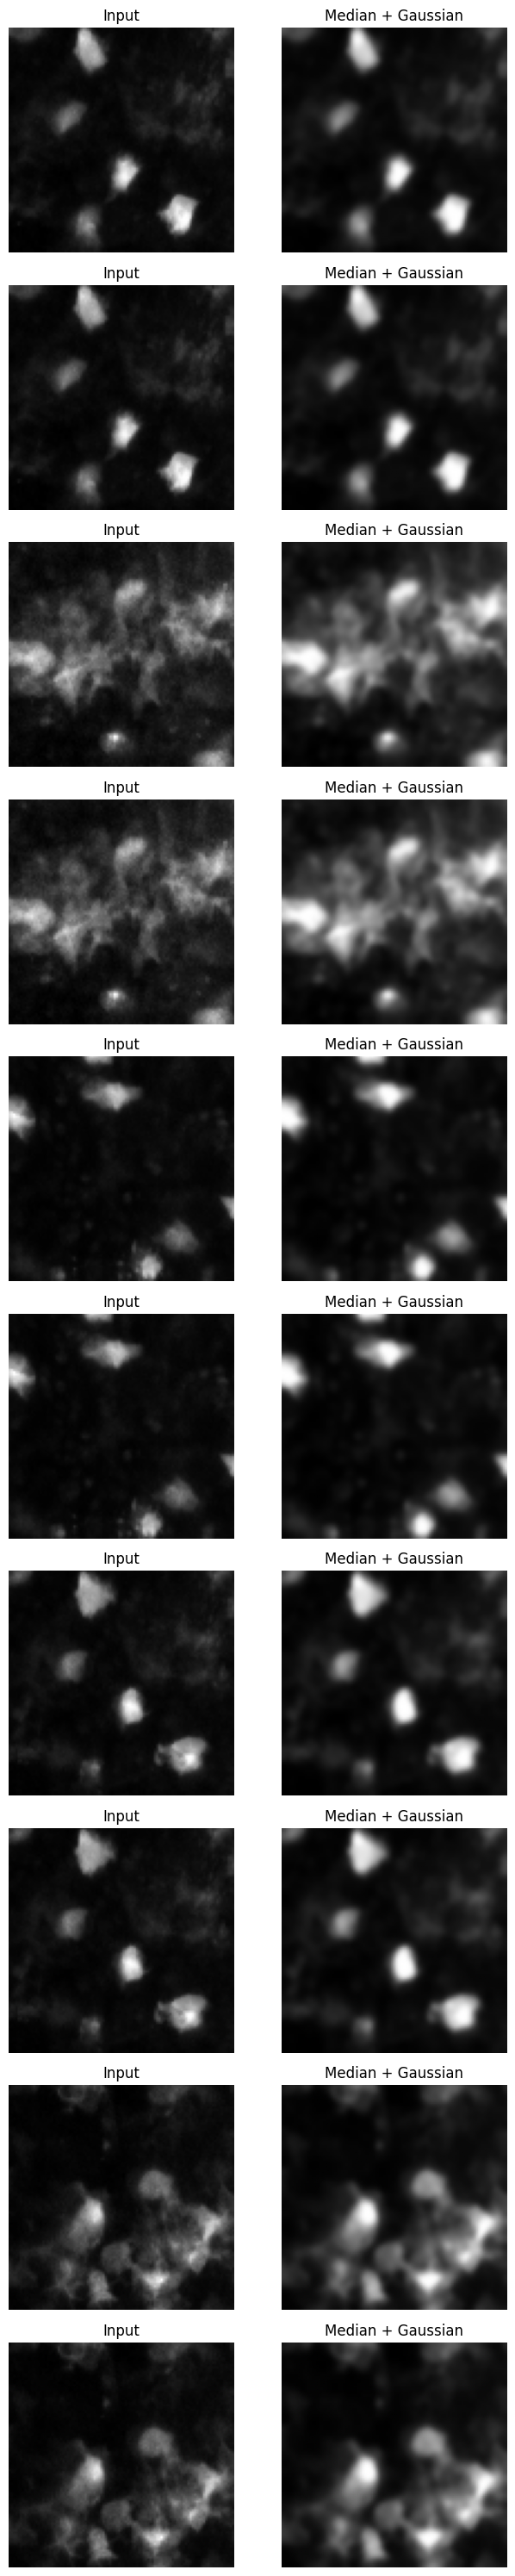

In [36]:
examples = image_features.head(10)
fig, axes = plt.subplots(len(examples), 2, figsize=(7, 3 * len(examples)), squeeze=False)
for row_axes, (_, example) in zip(axes, examples.iterrows()):
    row_axes[0].imshow(read_frame(example["image_path"]), cmap="gray")
    row_axes[1].imshow(io.imread(example["filtered_path"]), cmap="gray", vmin=0, vmax=255)
    for ax, title in zip(row_axes, ["Input", "Median + Gaussian"]):
        ax.set_title(title)
        ax.axis("off")
    row_axes[0].set_ylabel(Path(example["image_path"]).name)
fig.tight_layout()
plt.show()